In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score
)
from xgboost import XGBClassifier

# Load the original dataset (not the modified EDA dataframe)
df = pd.read_csv("HR-Analytics-Employee.csv")

# Check dataset dimensions
print("Dataset shape:", df.shape)


Dataset shape: (1470, 35)


In [2]:
# Remove the target, ID and constant columns
columns_to_drop = [
    "Attrition", "EmployeeNumber", "EmployeeCount",
    "Over18", "StandardHours"
]

# Define input features
X = df.drop(columns=columns_to_drop)

# Encode target: Leave = 1, Stay = 0
y = df["Attrition"].map({"Yes": 1, "No": 0})

# Check shapes
print("X:", X.shape)
print("y:", y.shape)


X: (1470, 30)
y: (1470,)


In [3]:
# Set aside 20% for testing and preserve the class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check the training distribution
print("Training:", X_train.shape)
print("Testing:", X_test.shape)
print("Train class proportions:")
print(y_train.value_counts(normalize=True).round(3))


Training: (1176, 30)
Testing: (294, 30)
Train class proportions:
Attrition
0    0.838
1    0.162
Name: proportion, dtype: float64


In [4]:
# Rating and level columns contain numbers but represent ordered categories.
# Treat each level as its own category rather than assuming a linear effect.
ordinal_cols = [
    "Education", "EnvironmentSatisfaction", "JobInvolvement",
    "JobLevel", "JobSatisfaction", "PerformanceRating",
    "RelationshipSatisfaction", "WorkLifeBalance"
]

# Separate continuous/count features from categorical features.
numeric_cols = [
    col for col in X_train.select_dtypes(include="number").columns
    if col not in ordinal_cols
]
categorical_cols = (
    X_train.select_dtypes(exclude="number").columns.tolist()
    + ordinal_cols
)

# Fit happens inside each training fold; validation and test are transformed only.
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])

print("Numeric columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))


Numeric columns: 15
Categorical columns: 15


In [5]:
# Define models with their initial settings
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "KNN": KNeighborsClassifier(),
    "SVM": SVC(),
    "XGBoost": XGBClassifier(random_state=42, eval_metric="logloss")
}

# Use the same 5 folds for all models
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Evaluate positive class = Leave (1)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]

# Collect cross-validation metrics for each model
baseline_results = []
for name, model in models.items():
    model_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    scores = cross_validate(
        model_pipeline, X_train, y_train, cv=cv, scoring=scoring
    )
    baseline_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "Avg Precision": scores["test_average_precision"].mean()
    })

# Display the baseline comparison
baseline_df = pd.DataFrame(baseline_results)
display(baseline_df.sort_values("F1", ascending=False).round(3))


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Avg Precision
0,Logistic Regression,0.889,0.764,0.458,0.569,0.851,0.670
5,XGBoost,0.872,0.717,0.337,0.451,0.793,0.562
1,Decision Tree,0.781,0.328,0.321,0.324,0.596,0.220
2,Random Forest,0.861,0.824,0.195,0.306,0.800,0.548
4,SVM,0.862,0.863,0.174,0.285,0.827,0.604
3,KNN,0.847,0.667,0.137,0.216,0.669,0.327


In [6]:
# Test whether extra weight for Leave improves F1 and Recall
class_weights = {
    "Default": None,
    "Weight 2": {0: 1, 1: 2},
    "Weight 3": {0: 1, 1: 3},
    "Balanced": "balanced"
}

weight_results = []
for name, weight in class_weights.items():
    weighted_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000, class_weight=weight))
    ])
    scores = cross_validate(
        weighted_pipeline, X_train, y_train, cv=cv, scoring=scoring
    )
    weight_results.append({
        "Weight": name,
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean()
    })

# Display results of weight experiments
weight_df = pd.DataFrame(weight_results)
display(weight_df.round(3))


,Weight,Precision,Recall,F1
0,Default,0.764,0.458,0.569
1,Weight 2,0.603,0.658,0.626
2,Weight 3,0.497,0.711,0.582
3,Balanced,0.408,0.758,0.528


In [8]:
# Use exactly the same preprocessing as in model comparison.
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

# Search different regularization strengths and class weights.
param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__class_weight": [None, {0: 1, 1: 2}, {0: 1, 1: 3}]
}

# CV selects the parameters; we will do the final fit explicitly in Cell 8.
grid_search = GridSearchCV(
    lr_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
    refit=False
)
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best selection CV F1:", round(grid_search.best_score_, 3))


Best parameters: {'model__C': 1, 'model__class_weight': {0: 1, 1: 2}}
Best selection CV F1: 0.626


              precision    recall  f1-score   support

        Stay       0.90      0.91      0.91       247
       Leave       0.50      0.49      0.49        47

    accuracy                           0.84       294
   macro avg       0.70      0.70      0.70       294
weighted avg       0.84      0.84      0.84       294

ROC-AUC: 0.835
Average Precision: 0.586


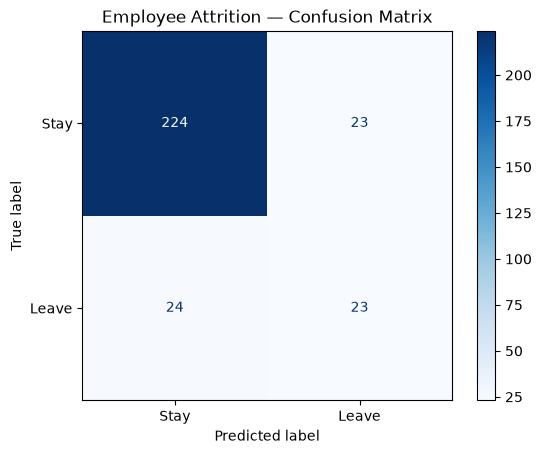

In [9]:
# Train once on all training rows using the selected parameters.
best_c = grid_search.best_params_["model__C"]
best_weight = grid_search.best_params_["model__class_weight"]

final_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        C=best_c,
        class_weight=best_weight,
        max_iter=1000
    ))
])
final_pipeline.fit(X_train, y_train)

# Evaluate on the held-out test set.
y_pred = final_pipeline.predict(X_test)
y_prob = final_pipeline.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=["Stay", "Leave"]))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))
print("Average Precision:", round(average_precision_score(y_test, y_prob), 3))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Stay", "Leave"], cmap="Blues"
)
plt.title("Employee Attrition — Confusion Matrix")
plt.show()


In [10]:
# Save preprocessing + model together for future predictions
joblib.dump(final_pipeline, "employee_attrition_model.joblib")
print("Model saved: employee_attrition_model.joblib")


Model saved: employee_attrition_model.joblib
